In [1]:
import numpy as np
import matplotlib.pyplot as plt
from joblib import Parallel, delayed
import pandas as pd
from scipy.linalg import expm, eigvals
from matplotlib.lines import Line2D
from itertools import product
import math

In [2]:
# GLOBAL STYLE SETTINGS (run once)

plt.rcParams.update({

    # --- FONT SIZES ---
    "font.size": 24,              # base font size
    "axes.titlesize": 20,         # title
    "axes.labelsize": 36,         # x/y labels
    "xtick.labelsize": 36,
    "ytick.labelsize": 36,
    "legend.fontsize": 16,

    # --- LINES ---
    "lines.linewidth": 5,
    "lines.markersize": 16,

    # --- FIGURE / AXIS ---
    "figure.figsize": (8, 6),
    "figure.dpi": 120,
    "axes.linewidth": 1.5,        # thicker axis spines

    # --- TICKS ---
    "xtick.major.size": 15,
    "xtick.major.width": 3,
    "ytick.major.size": 15,
    "ytick.major.width": 3,

    # --- LEGEND ---
    "legend.frameon": True,
    "legend.framealpha": 0.8,
    "legend.fancybox": True,
})


# Fig 1. (a)

In [6]:
def growth(Q, tau, nu, dt, PopSize=10**4, steps=None):
    if steps is None:
        steps = int(Q * tau / dt * 10)
    
    H = np.array([1] + [0]*(Q-1))
    indices = np.concatenate((np.arange(1, Q), [0]))
    Pop = np.random.multinomial(PopSize, [1/Q]*Q)
    AvH = [np.sum(Pop * H)/PopSize]
    
    Kswitch = int(tau/dt)
    
    for k in range(1, steps+1):
        # environmental switch
        if k > Kswitch:
            H = H[indices]
            Kswitch += int(tau/dt)
        
        # selection
        Proba = np.exp(H*dt) * Pop
        Proba /= np.sum(Proba)+1e-16
        Proba=np.maximum(0,Proba)
        Proba=np.minimum(1,Proba)
        Pop = np.random.multinomial(PopSize, Proba)
        # vectorized mutation / ν switching
        switch_out = np.random.binomial(Pop, nu*dt)
        stay = Pop - switch_out
        # redistribute switched individuals uniformly
        redistributed = np.random.multinomial(np.sum(switch_out), [1/Q]*Q)
        Pop = stay + redistributed
        
        AvH.append(np.sum(Pop * H)/PopSize)
    
    return np.mean(AvH[len(AvH)//2:])

# --- Accelerate for a list of nu values using parallelization ---
def growth_for_nu_list(Q, tau, nu_list, dt, PopSize=10**4, steps=None, n_jobs=-1):
    results = Parallel(n_jobs=n_jobs)(
        delayed(growth)(Q, tau, nu, dt, PopSize, steps) for nu in nu_list
    )
    return results

# === Model functions ===

def A_matrix(Hvec, mu, Q):
    """
    Continuous dynamics matrix, equivalent to Mathematica A[Hvec, mu, Q]
    """
    mat = np.full((Q, Q), mu/Q)
    np.fill_diagonal(mat, Hvec - mu*(Q-1)/Q)
    return mat

def Mcycle(Hvec, mu, Q, tau):
    """
    Full-cycle matrix over Q successive tau-intervals (Mathematica Mcycle)
    """
    matrices = []
    Hlist = [np.roll(Hvec, k) for k in range(Q)]  # Rotate Hvec
    for H in Hlist:
        matrices.append(expm(A_matrix(H, mu, Q)*tau))
    # Multiply in temporal order (last first)
    result = matrices[-1]
    for mat in matrices[-2::-1]:
        result = result @ mat
    return result

def rInf(Hvec, mu, Q, tau):
    """
    Asymptotic effective growth rate, equivalent to Mathematica rInf
    """
    mat = Mcycle(Hvec, mu, Q, tau)
    rho = max(np.abs(eigvals(mat)))
    return np.log(rho)/(Q*tau)

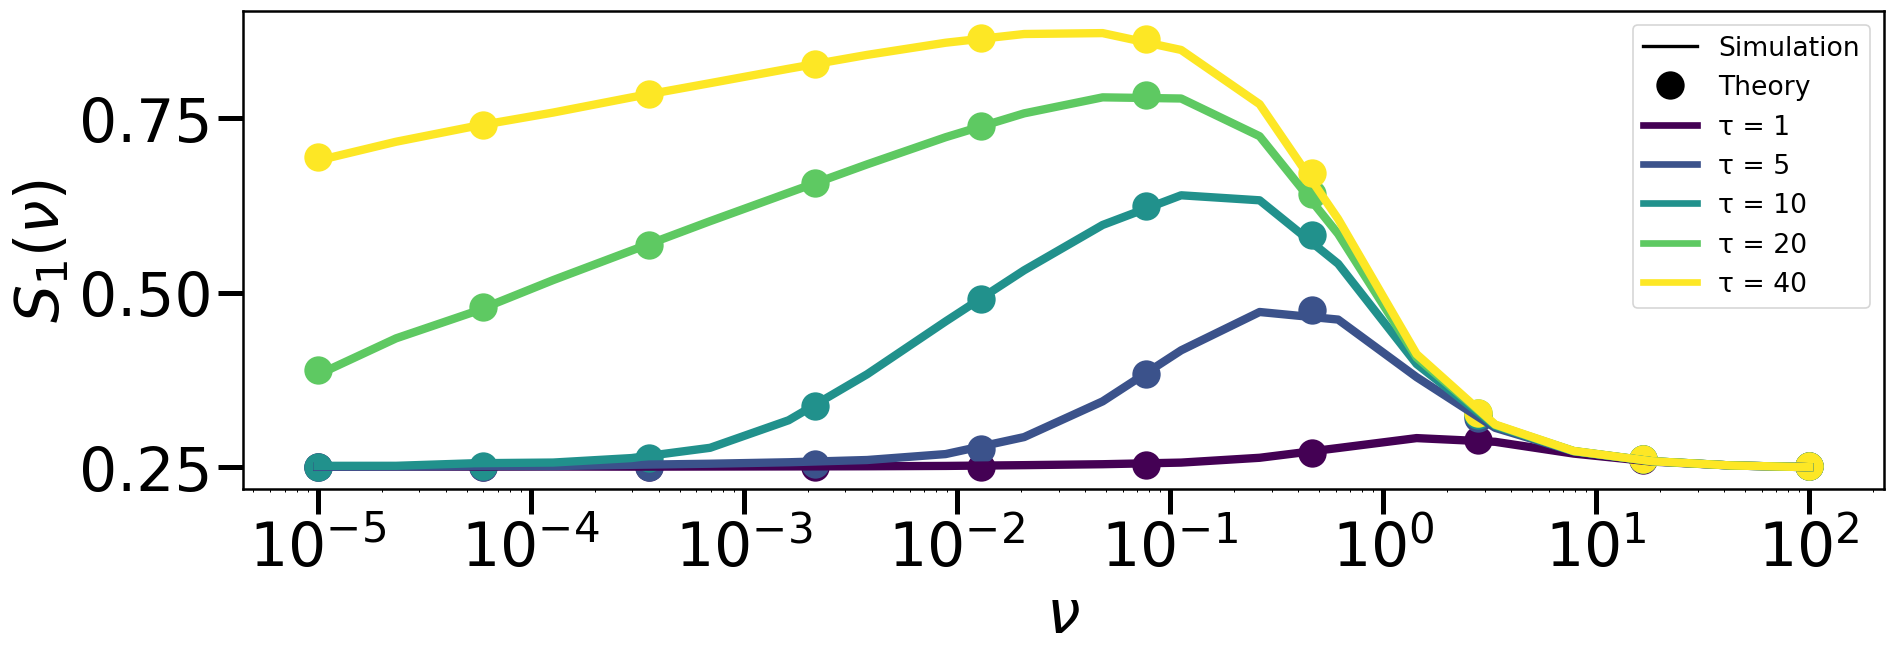

In [7]:
# === Parameters ===
Q = 4
Hvec = np.array([1.0] + [0.0]*(Q-1))
taus = [5, 10, 20, 40]
dt=1e-2
PopSize=10**8
mu_list = np.logspace(-5, 2, 100)  # equivalent to ν in your Mathematica code

# === Compute theory curves ===
theory_data = {}
for tau in taus:
    theory_data[tau] = [rInf(Hvec, mu, Q, tau) for mu in mu_list]

# === Optional: save to CSV to compare with simulation ===
df_list = []
for tau in taus:
    for mu, r in zip(mu_list, theory_data[tau]):
        df_list.append([tau, mu, r])
df_theory = pd.DataFrame(df_list, columns=["tau", "nu", "rInf"])
df_theory.to_csv("growth_data.csv", index=False)

# === Load simulation results (replace with your own growth_for_nu_list function) ===
# from your previous Monte Carlo simulations
# results_sim = growth_for_nu_list(Q, tau, mu_list, dt, PopSize)

# --- Plot ---
plt.figure(figsize=(16,6))
colors = plt.cm.viridis(np.linspace(0, 1, len(taus)))

for color, tau in zip(colors, taus):
    # --- Simulation (lines) ---
    nu_list = np.logspace(-5, 2, 20)
    results = growth_for_nu_list(Q, tau, nu_list, dt, PopSize)  # your stochastic sim
    plt.semilogx(nu_list, results, '-', color=color)

    # --- Theory (points) ---
    # Subsample points for clarity
    mu_list = np.logspace(-5, 2, 100)
    idx = np.linspace(0, len(mu_list)-1, min(10, len(mu_list)), dtype=int)
    plt.scatter(np.array(mu_list)[idx], np.array(theory_data[tau])[idx],
                color=color, marker='o')

# --- Custom legend ---
legend_lines = [Line2D([0], [0], color='k', lw=2, label='Simulation'),
                Line2D([0], [0], marker='o', color='w', markerfacecolor='k',
                       markeredgecolor='k', label='Theory')]

tau_handles = [Line2D([0], [0], color=color, lw=4, label=f'τ = {tau}') 
               for color, tau in zip(colors, taus)]

plt.legend(handles=legend_lines + tau_handles)
plt.xlabel(r"$\nu$")
plt.ylabel(r"$S_1(\nu)$")
plt.xscale("log")
plt.tight_layout()
plt.savefig('S_1_nu.svg')
plt.show()

# Fig 1. (b)

5
10
15


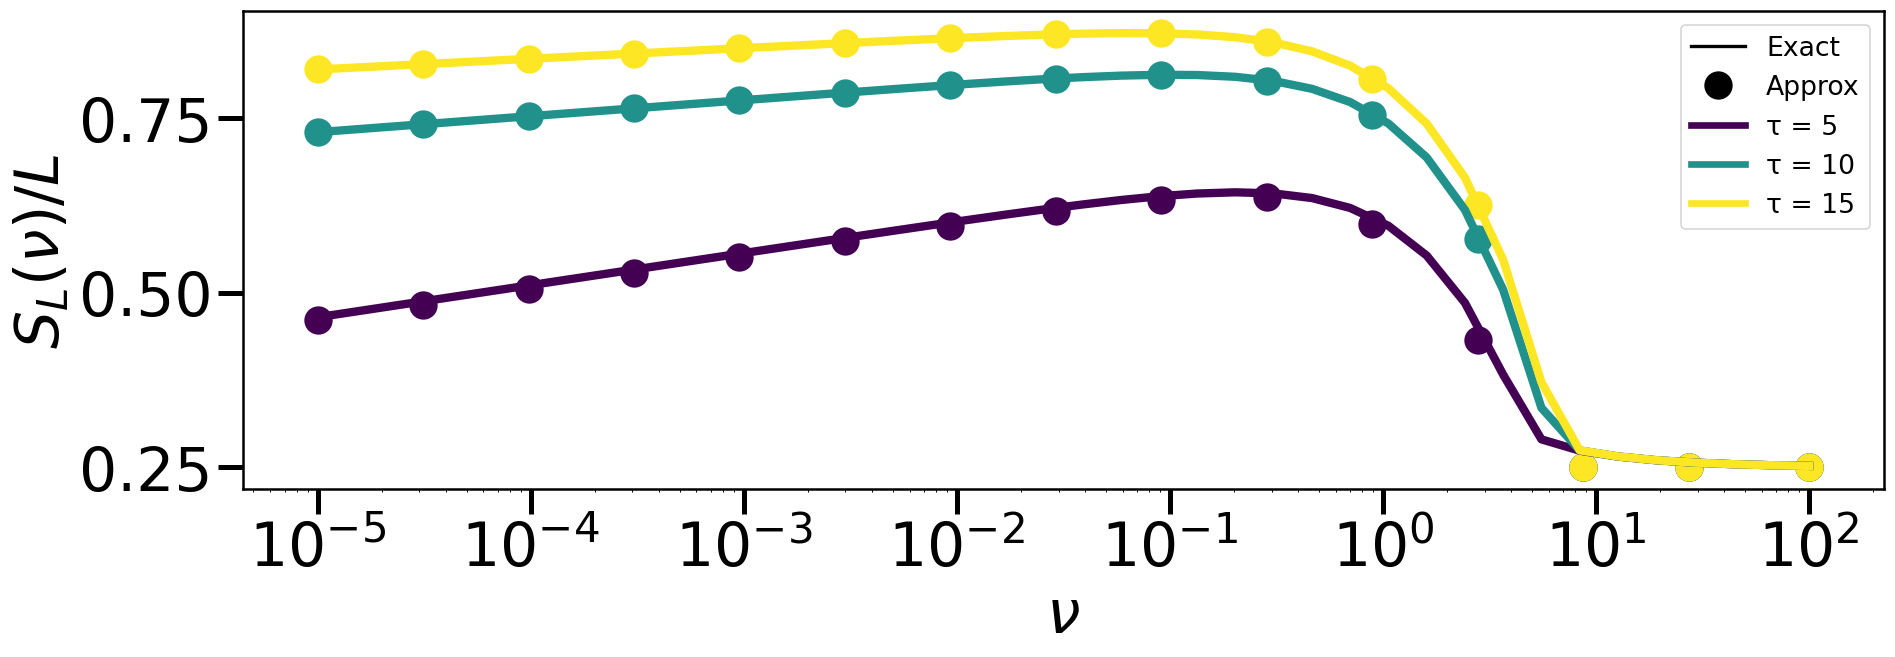

In [4]:
# --- Reduced exact Q=4 ---
def r_inf_exact_Q4(L, tau, nu):
    Ks= [(k1, k2, k3) for k1, k2, k3 in product(range(L+1), repeat=3) if k1 + k2 + k3 <= L]
    m = np.array([(
    math.comb(L, k1)
    * math.comb(L - k1, k2)
    * math.comb(L - k1 - k2, k3)
) for (k1,k2,k3) in Ks])
    A0 = (nu / Q**L) * np.outer(np.sqrt(m), np.sqrt(m))
    A1 = A0.copy()
    A2=A0.copy()
    A3=A0.copy()
    A0 += np.diag([k0 - nu for (k0,k1,k2) in Ks])
    A1 += np.diag([k1 - nu for (k0,k1,k2) in Ks])
    A2 += np.diag([k2 - nu for (k0,k1,k2) in Ks])
    A3 += np.diag([L-k1-k2-k3 - nu for (k1,k2,k3) in Ks])
    M = expm(A3 * tau) @expm(A2 * tau) @expm(A1 * tau) @ expm(A0 * tau)
    lam_max = np.max(np.real(np.linalg.eigvals(M)))
    return np.log(lam_max) / (4 * tau)


# === Parameters ===
Q = 4
L=10
Hvec = np.array([1.0] + [0.0]*(Q-1))
taus = [5, 10, 15]
dt=1e-1
mu_list = np.logspace(-5, 2, 100)  
nu_list=np.logspace(-5,2,40)
# === Compute theory curves ===
theory_data = {}
for tau in taus:
    theory_data[tau] = np.maximum(L/Q,L-mu_list*(1-Q**(-L))+np.log(2*mu_list/Q**L/L)/tau)/L




# --- Plot ---
plt.figure(figsize=(16,6))
colors = plt.cm.viridis(np.linspace(0, 1, len(taus)))

for color, tau in zip(colors, taus):
    print(tau)
    results=[r_inf_exact_Q4(L, tau, nu)/L for nu in nu_list]
    plt.semilogx(nu_list, results, '-', color=color)

    # --- Theory (points) ---
    # Subsample points for clarity
    idx = np.linspace(0, len(mu_list)-1, min(15, len(mu_list)), dtype=int)
    plt.scatter(np.array(mu_list)[idx], np.array(theory_data[tau])[idx],
                color=color, marker='o')

# --- Custom legend ---
legend_lines = [Line2D([0], [0], color='k', lw=2, label='Exact'),
                Line2D([0], [0], marker='o', color='w', markerfacecolor='k',
                       markeredgecolor='k', label='Approx')]

tau_handles = [Line2D([0], [0], color=color, lw=4, label=f'τ = {tau}') 
               for color, tau in zip(colors, taus)]

plt.legend(handles=legend_lines + tau_handles)
plt.xlabel(r"$\nu$")
plt.ylabel(r"$S_L(\nu)/L$")
plt.xscale("log")
plt.tight_layout()
plt.savefig('Effective_Growth_VR_L10.svg')
plt.show()



# Fig 1. (c)

In [9]:
def growth_competing(Q, tau, mu, nu, dt, PopSize=10**4, steps=None):
    """
    Two competing types in SAME population:
        Type A mutates at rate μ
        Type B mutates at rate ν
    Both experience identical environment H(t)
    They compete for fixed total population size PopSize.
    """

    if steps is None:
        steps = int(Q * tau / dt * 20)

    # environment vector
    H = np.array([1] + [0]*(Q-1))
    indices = np.concatenate((np.arange(1, Q), [0]))

    # initial populations (split 50/50)
    PopA = np.random.multinomial(PopSize//2, [1/Q]*Q)
    PopB = np.random.multinomial(PopSize - PopSize//2, [1/Q]*Q)

    freqA = []   # total fraction of Type A
    freqB = []   # total fraction of Type B

    Kswitch = int(tau/dt)

    for k in range(1, steps+1):

        # ---- rotate environment ----
        if k > Kswitch:
            H = H[indices]
            Kswitch += int(tau/dt)

        expH = np.exp(H*dt)

        # ---- SELECTION: COMPETITIVE REPRODUCTION ----
        # fitness-weighted numbers
        WA = expH * PopA
        WB = expH * PopB
        totalW = WA.sum() + WB.sum()

        # probability of drawing each state *from both types combined*
        Pstates = (WA + WB) / (totalW + 1e-16)

        # NEW total population
        Pop_new = np.random.multinomial(PopSize, Pstates)

        # ---- Now split Pop_new back into A vs B proportionally ----
        fracA_state = WA / (WA + WB + 1e-16)
        fracA_state = np.nan_to_num(fracA_state, nan=0.5)

        PopA = np.random.binomial(Pop_new, fracA_state)
        PopB = Pop_new - PopA

        # ---- MUTATION DIFFERENT FOR A AND B ----
        # Type A uses μ
        outA = np.random.binomial(PopA, mu*dt)
        stayA = PopA - outA
        redA = np.random.multinomial(outA.sum(), [1/Q]*Q)
        PopA = stayA + redA

        # Type B uses ν
        outB = np.random.binomial(PopB, nu*dt)
        stayB = PopB - outB
        redB = np.random.multinomial(outB.sum(), [1/Q]*Q)
        PopB = stayB + redB

        # ---- record frequencies ----
        freqA.append(PopA.sum() / PopSize)
        freqB.append(PopB.sum() / PopSize)

    return np.array(freqA), np.array(freqB)

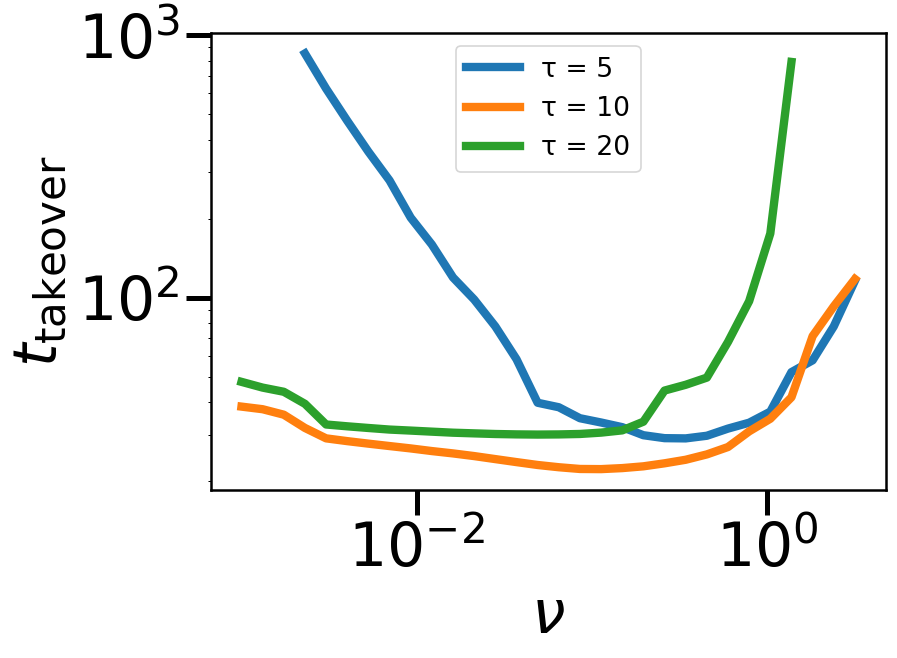

In [10]:
Q = 4
taus = [5, 10, 20]
nu_lis = np.logspace(-3, 0.5, 30)
dt = 1e-1
PopSize = 10**8
steps = 10**4
n_jobs = -1  # use all available cores
n_repeats = 10  # average over 10 runs

# --- Function to compute takeover time for a single nu (single run) ---
def compute_T_single(nu, tau):
    fA, fB = growth_competing(Q, tau, 1e-5, nu, dt, PopSize=PopSize, steps=steps)
    indices = np.where(fB > 0.995)[0]
    if len(indices) == 0:
        return np.inf
    return indices[0] * dt

# --- Function to compute average takeover time over n_repeats ---
def compute_T_avg(nu, tau, repeats=n_repeats):
    results = [compute_T_single(nu, tau) for _ in range(repeats)]
    return np.mean(results)

# --- Loop over taus ---
plt.figure(figsize=(8,6))

for tau in taus:
    # Parallel computation over nu_lis
    T_avg = Parallel(n_jobs=n_jobs)(
        delayed(compute_T_avg)(nu, tau, n_repeats) for nu in nu_lis
    )
    T_avg = np.array(T_avg)
    plt.plot(nu_lis[T_avg < np.inf], T_avg[T_avg < np.inf], label=f"τ = {tau}")

plt.xlabel(r"$\nu$")
plt.ylabel(r"$t_\mathrm{takeover}$")
plt.xscale("log")
plt.yscale("log")
plt.legend()
plt.tight_layout()
#plt.savefig("TakeOverTime_tau5_tau20_limited_avg10.svg")
plt.show()

# Fig 1. (d)

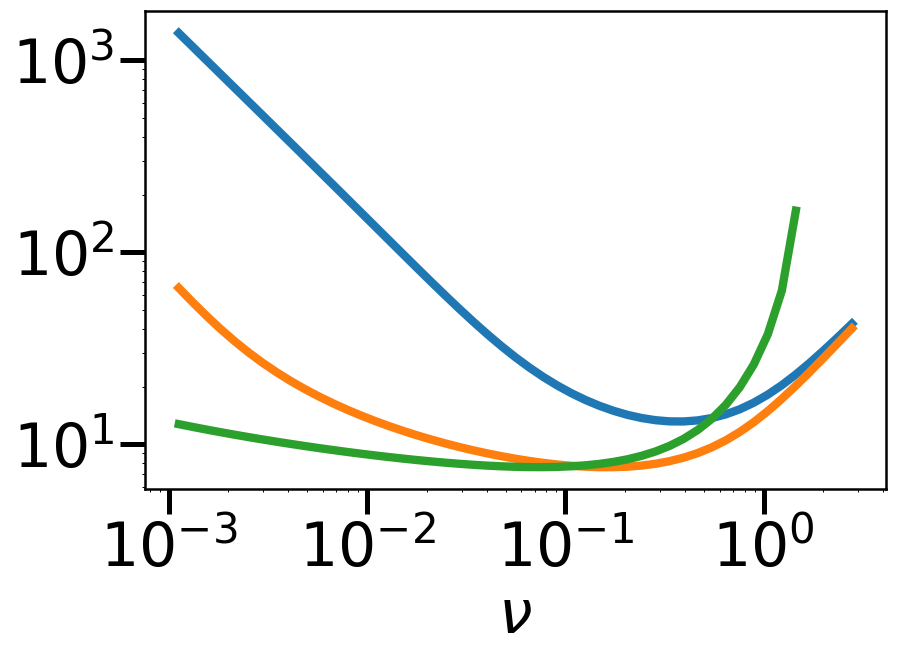

In [14]:
# --- parameters ---
mu = 1e-5
taus_to_plot = [5 , 10, 20]

# === Load theoretical data ===
df_full = pd.read_csv("growth_data.csv")

# --- Ensure numeric types ---
df_full["nu"] = pd.to_numeric(df_full["nu"], errors="raise")
df_full["tau"] = pd.to_numeric(df_full["tau"], errors="raise")
df_full["rInf"] = pd.to_numeric(df_full["rInf"], errors="raise")

# === Extract rInf(mu) BEFORE restricting the nu-range ===
rInf_mu = {}
for tau in taus_to_plot:
    subset = df_full[(df_full["tau"] == tau) & (np.isclose(df_full["nu"].to_numpy(), mu))]
    if len(subset) == 0:
        raise ValueError(f"No entry for nu = {mu} at tau = {tau}")
    rInf_mu[tau] = subset["rInf"].values[0]

# === Now restrict ν-range AFTERWARD ===
nu_min, nu_max = 1e-3, 10**0.5
df = df_full[(df_full["nu"] >= nu_min) & (df_full["nu"] <= nu_max)]

# === Plot ===
plt.figure(figsize=(8,6))

for tau in taus_to_plot:
    group = df[df["tau"] == tau].sort_values("nu")
    
    # compute rInf(ν) - rInf(μ)
    diff = group["rInf"] - rInf_mu[tau]
    valid = diff > 0
    nu_valid = group["nu"][valid]
    inv_valid = -np.log(0.05) / diff[valid]

    plt.plot(nu_valid, inv_valid, label=f"τ = {tau}")

plt.xlabel(r"$\nu$")
plt.xscale("log")
plt.yscale("log")
plt.tight_layout()
#plt.savefig("InverseGrowthDifference_tau5_tau20_limited.svg")
plt.show()
